# PREDICTIVE ANALYTICS: DIABETES RISK PREDICTION

BUSINESS UNDERSTANDING & PROBLEM STATEMENT
==========================================
Diabetes adalah salah satu penyakit kronis yang paling umum di dunia dengan
prevalensi yang terus meningkat. Deteksi dini risiko diabetes sangat penting
untuk pencegahan dan pengelolaan yang efektif.

GOALS:
1. Mengembangkan model prediksi risiko diabetes berdasarkan faktor-faktor kesehatan
2. Mengidentifikasi faktor-faktor yang paling berpengaruh terhadap risiko diabetes
3. Memberikan probabilitas risiko untuk membantu keputusan medis

APPROACH:
- Menggunakan supervised learning (klasifikasi biner)
- Membandingkan beberapa algoritma machine learning
- Melakukan hyperparameter tuning untuk optimasi
- Evaluasi menggunakan multiple metrics yang relevan untuk medical diagnosis

SOLUTION STATEMENT:
- Logistic Regression sebagai baseline model
- Random Forest untuk handling non-linear relationships
- XGBoost untuk advanced ensemble learning dengan tuning

## 1. IMPORT LIBRARIES DAN SETUP


Pada tahap ini, kita akan mengimpor semua library yang dibutuhkan untuk analisis, preprocessing, modeling, dan evaluasi.  
- Library dasar: pandas, numpy, matplotlib, seaborn.  
- Library preprocessing dan model: scikit-learn, (XGBoost jika tersedia).  
- Utility: joblib (untuk menyimpan model), datetime, os, Google Drive untuk mounting dataset.

In [1]:
!pip install xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning Libraries
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV,
    StratifiedKFold, validation_curve
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("⚠️ XGBoost not available. Using alternative models.")

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    make_scorer
)

# Utilities
import joblib
from datetime import datetime
import os
from google.colab import drive
import zipfile
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Tentukan path ZIP dan folder ekstraksi
zip_path = '/content/drive/MyDrive/dataset/submission/dataset.zip'  # ganti sesuai lokasi
extract_to = '/content/dataset'
file_path = '/content/dataset/diabetes_prediction_dataset.csv'

# 3. Ekstrak jika belum ada foldernya
if not os.path.exists(extract_to):
    os.makedirs(extract_to)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print("✅ Dataset berhasil diekstrak ke", extract_to)
else:
    print("⚠️ Folder sudah ada, melewati ekstraksi.")

# Visualization Settings
plt.style.use('default')  # Changed from 'seaborn-v0_8' for compatibility
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)

print("📊 Libraries imported successfully!")
print(f"Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⚠️ Folder sudah ada, melewati ekstraksi.
📊 Libraries imported successfully!
Timestamp: 2025-05-31 20:35:14


## 2. SAMPLE DATA GENERATION


Membuat data sampel sintetik jika dataset tidak dapat digunakan
1. Meng-generate dataset sintetis dengan `n_samples=10000`.  
2. Menjelaskan fitur yang dihasilkan (age, gender, BMI, dst.) beserta logika pembuatan target `diabetes`.  
3. Data ini akan dipakai untuk demonstrasi seluruh pipeline sehingga Notebook dapat berjalan tanpa error.


In [3]:
def generate_sample_diabetes_data(n_samples=10000):

    np.random.seed(42)

    # Generate features
    data = {}

    # Age (20-80 years)
    data['age'] = np.random.normal(45, 15, n_samples).clip(20, 80)

    # Gender
    data['gender'] = np.random.choice(['Male', 'Female'], n_samples)

    # BMI (15-50)
    data['bmi'] = np.random.normal(25, 5, n_samples).clip(15, 50)

    # Hypertension (0 or 1)
    data['hypertension'] = np.random.binomial(1, 0.3, n_samples)

    # Heart Disease (0 or 1)
    data['heart_disease'] = np.random.binomial(1, 0.2, n_samples)

    # Smoking History
    smoking_options = ['never', 'former', 'current', 'not current', 'ever', 'No Info']
    data['smoking_history'] = np.random.choice(smoking_options, n_samples)

    # HbA1c Level (4-10)
    data['HbA1c_level'] = np.random.normal(5.5, 1.2, n_samples).clip(4, 10)

    # Blood Glucose Level (80-300)
    data['blood_glucose_level'] = np.random.normal(120, 40, n_samples).clip(80, 300)

    df = pd.DataFrame(data)

    # Generate target based on logical rules
    diabetes_prob = (
        0.1 +  # baseline
        0.3 * (df['age'] > 60) +
        0.4 * (df['bmi'] > 30) +
        0.3 * df['hypertension'] +
        0.2 * df['heart_disease'] +
        0.4 * (df['HbA1c_level'] > 6.5) +
        0.5 * (df['blood_glucose_level'] > 140) +
        0.1 * (df['smoking_history'].isin(['current', 'former']))
    )

    diabetes_prob = np.clip(diabetes_prob, 0, 1)
    data['diabetes'] = np.random.binomial(1, diabetes_prob, n_samples)

    return pd.DataFrame(data)

## 3. DATA LOADING DAN INITIAL EXPLORATION


Pada tahap ini, kita membuat fungsi `load_and_explore_data` yang:
1. Mencoba memuat data dari file CSV (`file_path`).  
2. Jika tidak ada, langsung memanggil `generate_sample_diabetes_data()` untuk menghasilkan dataset sintetik.  
3. Menampilkan:
   - Shape (jumlah baris, kolom).
   - Daftar kolom dan tipe datanya.
   - Informasi missing values (jika ada).
   - Contoh 5 baris pertama (`head()`).
4. mengambil 10.000 data untuk di proses dari dataset

In [4]:
def load_and_explore_data(file_path=None):
    """
    Load dataset dan melakukan initial exploration
    """
    print("=" * 60)
    print("🔍 DATA LOADING & INITIAL EXPLORATION")
    print("=" * 60)

    try:
        if file_path and os.path.exists(file_path):
            df = pd.read_csv(file_path)
            print(f"✅ Dataset berhasil dimuat dari {file_path}!")
        else:
            print("📋 Generating sample dataset for demonstration...")
            df = generate_sample_diabetes_data()
            print("✅ Sample dataset generated!")

        print(f"📏 Shape: {df.shape} (rows: {df.shape[0]}, columns: {df.shape[1]})")

        # Basic Info
        print("\n📋 Dataset Info:")
        print(f"Columns: {list(df.columns)}")
        print(f"Data types: {df.dtypes.to_dict()}")

        # Missing Values
        print("\n❓ Missing Values:")
        missing_info = df.isnull().sum()
        missing_percent = (missing_info / len(df)) * 100
        missing_df = pd.DataFrame({
            'Missing Count': missing_info,
            'Missing Percentage': missing_percent
        })
        missing_summary = missing_df[missing_df['Missing Count'] > 0]
        if len(missing_summary) > 0:
            print(missing_summary)
        else:
            print("No missing values found!")

        # Basic Statistics
        print("\n📊 Dataset Sample:")
        print(df.head())

        return df

    except Exception as e:
        print(f"❌ Error loading data: {e}")
        return None

# Load dataset
df_real = load_and_explore_data('dataset/diabetes_prediction_dataset.csv')
df = df_real.sample(n=20000, random_state=42).reset_index(drop=True)

🔍 DATA LOADING & INITIAL EXPLORATION
✅ Dataset berhasil dimuat dari dataset/diabetes_prediction_dataset.csv!
📏 Shape: (100000, 9) (rows: 100000, columns: 9)

📋 Dataset Info:
Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']
Data types: {'gender': dtype('O'), 'age': dtype('float64'), 'hypertension': dtype('int64'), 'heart_disease': dtype('int64'), 'smoking_history': dtype('O'), 'bmi': dtype('float64'), 'HbA1c_level': dtype('float64'), 'blood_glucose_level': dtype('int64'), 'diabetes': dtype('int64')}

❓ Missing Values:
No missing values found!

📊 Dataset Sample:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  

## 4. EXPLORATORY DATA ANALYSIS (EDA)


Pada tahap EDA, kita ingin:
1. Memahami distribusi target (`diabetes`): proporsi positif vs negatif.  
2. Melihat distribusi fitur numerik (`age`, `bmi`, `HbA1c_level`, `blood_glucose_level`) berdasarkan status `diabetes` (histogram, boxplot, violin).  
3. Menampilkan ringkasan statistik (mean, median, std) per kelompok `diabetes`.  
4. Menganalisis korelasi antar fitur numerik beserta `diabetes`.  
5. Menganalisis fitur kategorikal (`gender`, `hypertension`, `heart_disease`, `smoking_history`) terhadap `diabetes`.  
6. Membuat kategori umur (`age_group`) dan melihat bagaimana `diabetes` terdistribusi pada tiap kelompok umur.  

Penjelasan:
- Visualisasi ini membantu kita mengenali pola awal—misalnya, apakah orang dengan BMI tinggi lebih banyak yang diabetic?
- Korelasi juga memberikan ide fitur mana yang bisa sangat berpengaruh ke model.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               20000 non-null  object 
 1   age                  20000 non-null  float64
 2   hypertension         20000 non-null  int64  
 3   heart_disease        20000 non-null  int64  
 4   smoking_history      20000 non-null  object 
 5   bmi                  20000 non-null  float64
 6   HbA1c_level          20000 non-null  float64
 7   blood_glucose_level  20000 non-null  int64  
 8   diabetes             20000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 1.4+ MB



📈 EXPLORATORY DATA ANALYSIS


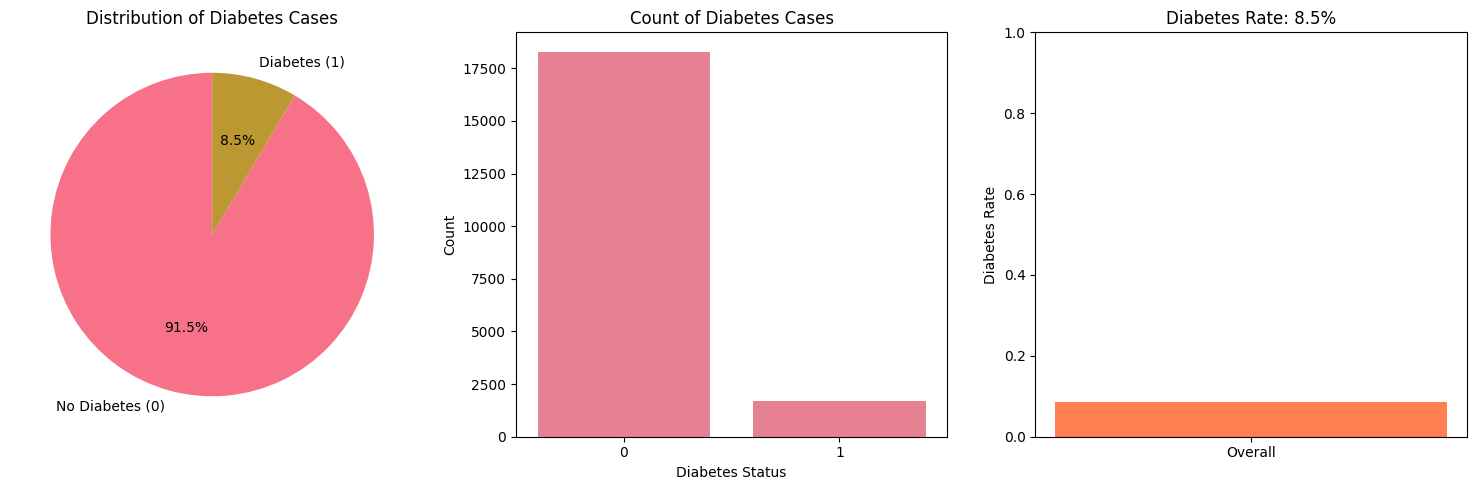

📊 Diabetes Distribution:
   - No Diabetes: 18,292 (91.5%)
   - Diabetes: 1,708 (8.5%)


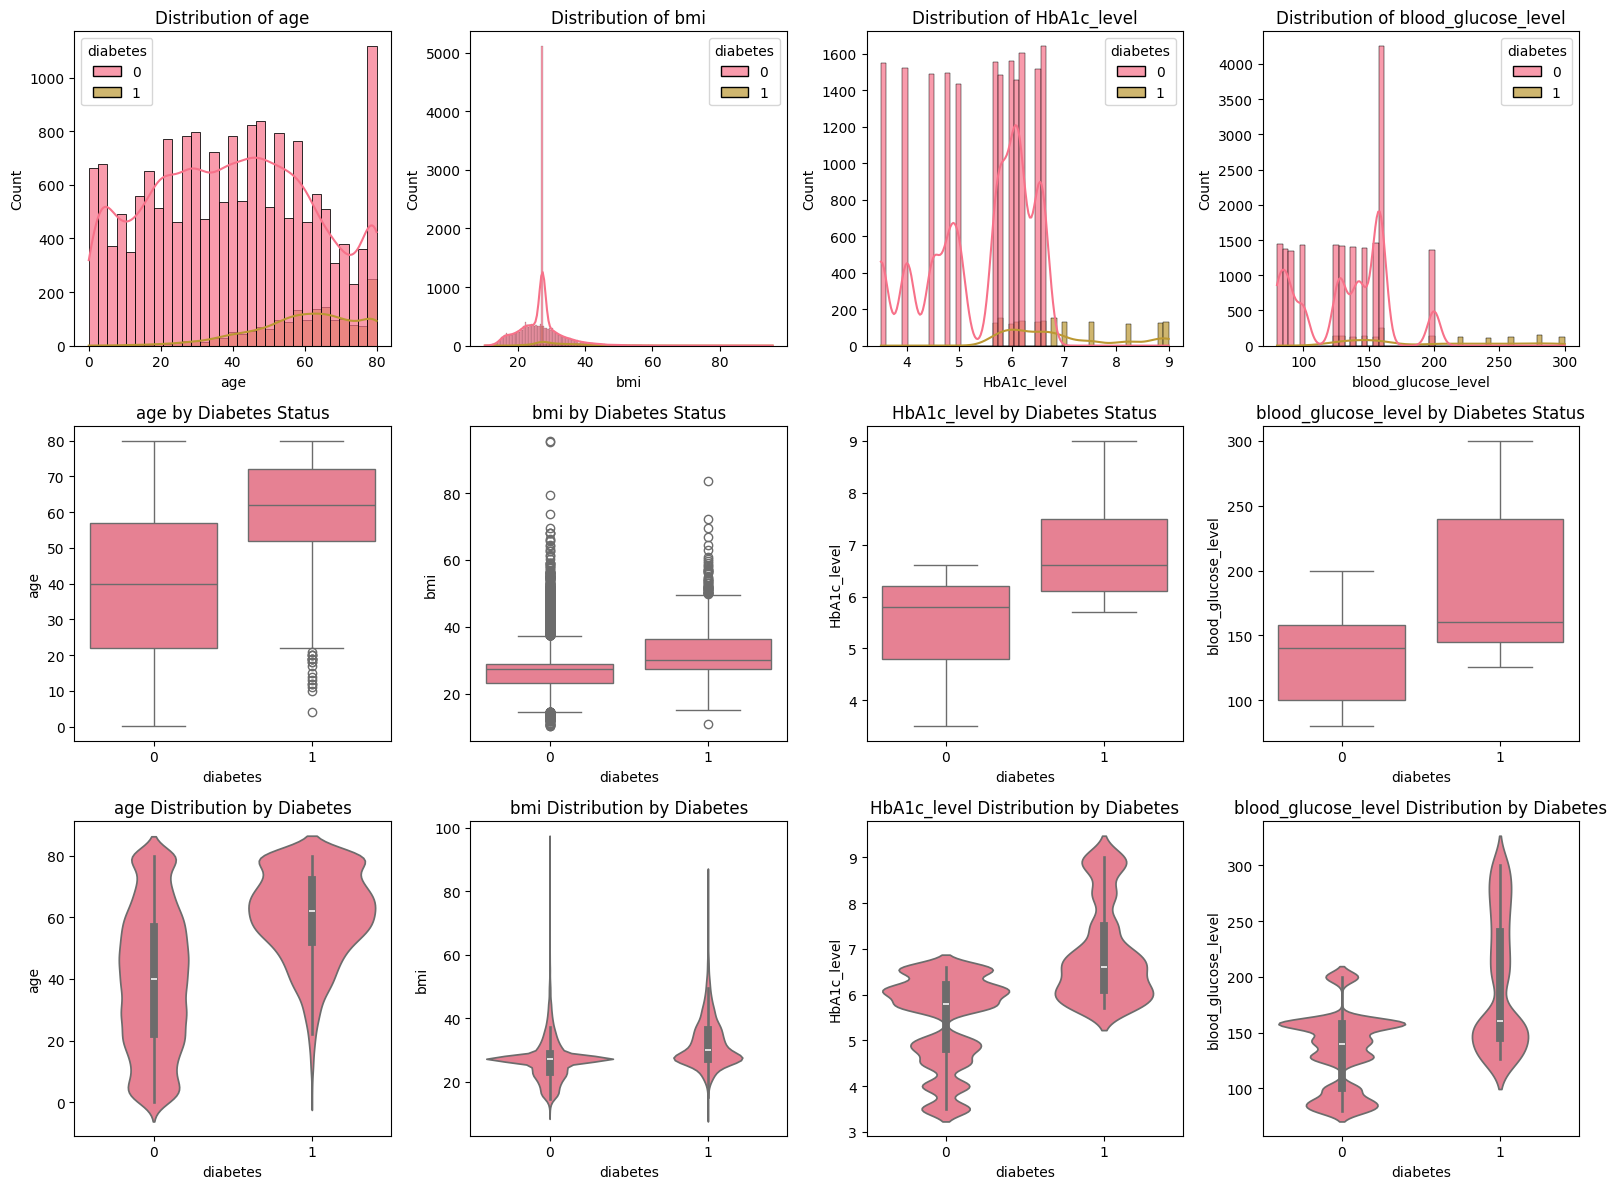


📊 Statistical Summary by Diabetes Status:
            age                  bmi              HbA1c_level               \
           mean median    std   mean median   std        mean median   std   
diabetes                                                                     
0         39.72   40.0  22.40  26.84  27.32  6.45        5.40    5.8  0.98   
1         60.53   62.0  14.36  32.16  29.98  7.58        6.92    6.6  1.06   

         blood_glucose_level                
                        mean median    std  
diabetes                                    
0                     132.89  140.0  34.13  
1                     193.68  160.0  58.77  


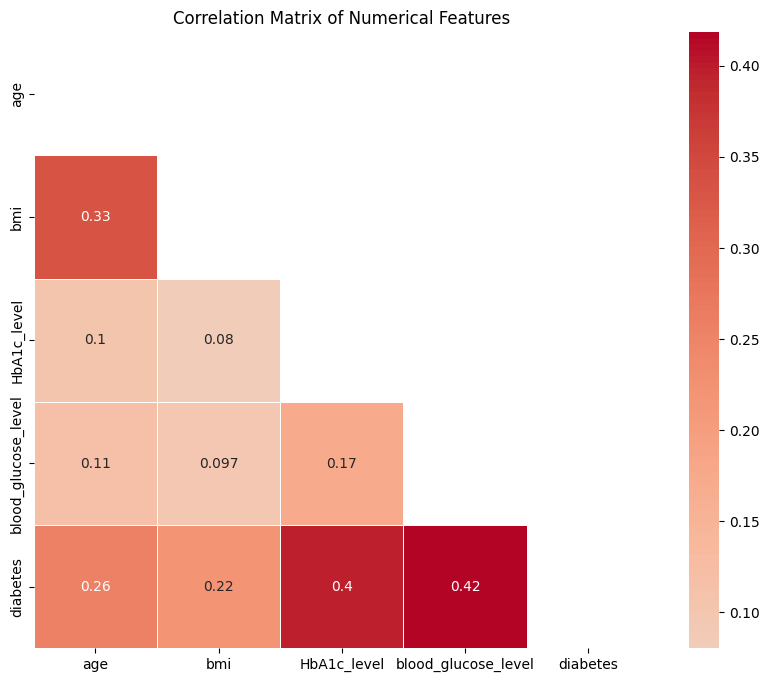

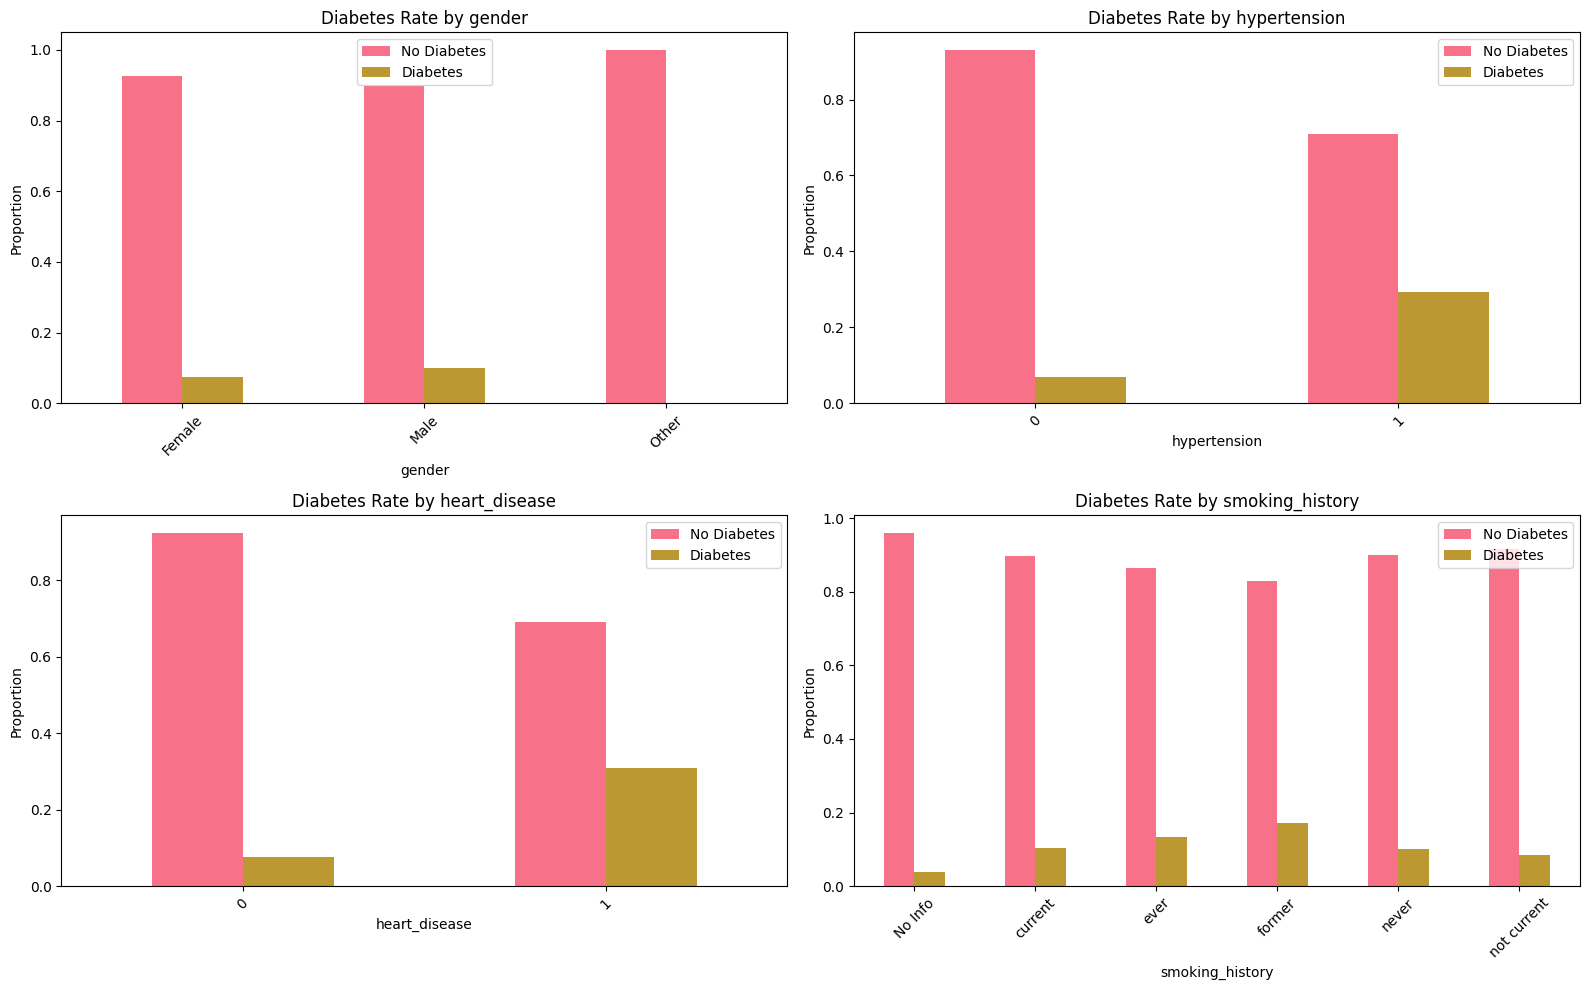

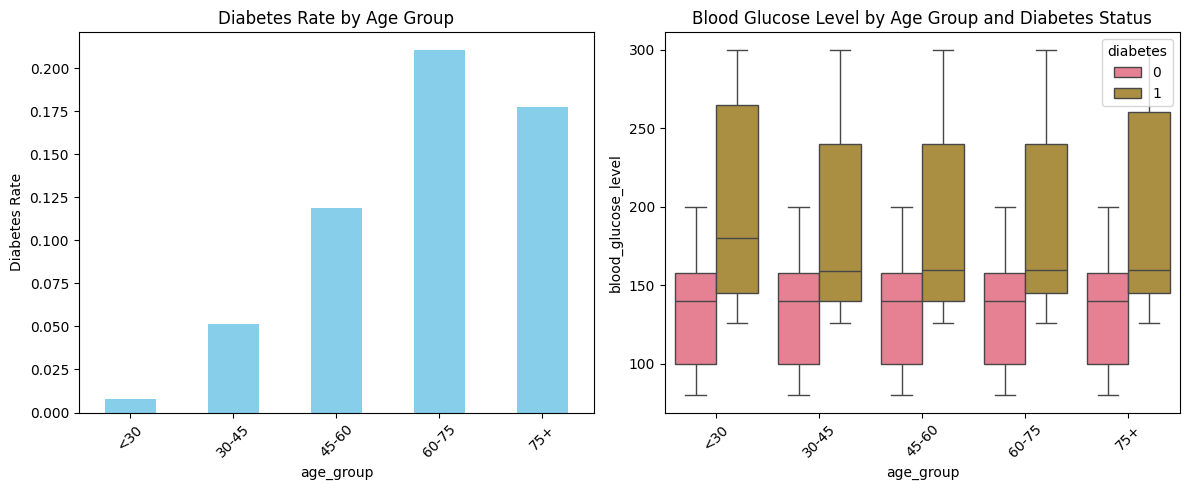

In [6]:
def perform_comprehensive_eda(df):
    """
    Melakukan Exploratory Data Analysis yang komprehensif
    """
    print("\n" + "=" * 60)
    print("📈 EXPLORATORY DATA ANALYSIS")
    print("=" * 60)

    # 4.1 Target Variable Distribution
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    diabetes_counts = df['diabetes'].value_counts()
    plt.pie(diabetes_counts.values, labels=['No Diabetes (0)', 'Diabetes (1)'],
            autopct='%1.1f%%', startangle=90)
    plt.title('Distribution of Diabetes Cases')

    plt.subplot(1, 3, 2)
    sns.countplot(data=df, x='diabetes')
    plt.title('Count of Diabetes Cases')
    plt.xlabel('Diabetes Status')
    plt.ylabel('Count')

    plt.subplot(1, 3, 3)
    diabetes_rate = df['diabetes'].mean()
    plt.bar(['Overall'], [diabetes_rate], color='coral')
    plt.title(f'Diabetes Rate: {diabetes_rate:.1%}')
    plt.ylabel('Diabetes Rate')
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()

    print(f"📊 Diabetes Distribution:")
    print(f"   - No Diabetes: {diabetes_counts[0]:,} ({diabetes_counts[0]/len(df)*100:.1f}%)")
    print(f"   - Diabetes: {diabetes_counts[1]:,} ({diabetes_counts[1]/len(df)*100:.1f}%)")

    # 4.2 Numerical Features Analysis
    numerical_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

    plt.figure(figsize=(16, 12))
    for i, col in enumerate(numerical_cols, 1):
        # Distribution plot
        plt.subplot(3, 4, i)
        sns.histplot(data=df, x=col, hue='diabetes', kde=True, alpha=0.7)
        plt.title(f'Distribution of {col}')

        # Box plot
        plt.subplot(3, 4, i+4)
        sns.boxplot(data=df, x='diabetes', y=col)
        plt.title(f'{col} by Diabetes Status')

        # Violin plot
        plt.subplot(3, 4, i+8)
        sns.violinplot(data=df, x='diabetes', y=col)
        plt.title(f'{col} Distribution by Diabetes')

    plt.tight_layout()
    plt.show()

    # 4.3 Statistical Summary
    print("\n📊 Statistical Summary by Diabetes Status:")
    summary_stats = df.groupby('diabetes')[numerical_cols].agg(['mean', 'median', 'std']).round(2)
    print(summary_stats)

    # 4.4 Correlation Analysis
    plt.figure(figsize=(10, 8))
    correlation_matrix = df[numerical_cols + ['diabetes']].corr()
    mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
    sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap='coolwarm',
                center=0, square=True, linewidths=.5)
    plt.title('Correlation Matrix of Numerical Features')
    plt.show()

    # 4.5 Categorical Features Analysis
    categorical_cols = ['gender', 'hypertension', 'heart_disease', 'smoking_history']

    plt.figure(figsize=(16, 10))
    for i, col in enumerate(categorical_cols, 1):
        plt.subplot(2, 2, i)
        crosstab = pd.crosstab(df[col], df['diabetes'], normalize='index')
        crosstab.plot(kind='bar', ax=plt.gca())
        plt.title(f'Diabetes Rate by {col}')
        plt.ylabel('Proportion')
        plt.legend(['No Diabetes', 'Diabetes'])
        plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

    # 4.6 Age Group Analysis
    df['age_group'] = pd.cut(df['age'],
                            bins=[0, 30, 45, 60, 75, 100],
                            labels=['<30', '30-45', '45-60', '60-75', '75+'])

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    age_diabetes = df.groupby('age_group')['diabetes'].agg(['count', 'sum', 'mean'])
    age_diabetes['rate'] = age_diabetes['mean']
    age_diabetes['rate'].plot(kind='bar', color='skyblue')
    plt.title('Diabetes Rate by Age Group')
    plt.ylabel('Diabetes Rate')
    plt.xticks(rotation=45)

    plt.subplot(1, 2, 2)
    sns.boxplot(data=df, x='age_group', y='blood_glucose_level', hue='diabetes')
    plt.title('Blood Glucose Level by Age Group and Diabetes Status')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

    return df

# Perform EDA
df_analyzed = perform_comprehensive_eda(df)

### Penjelasan:
- **Distribusi target** (pie chart dan countplot) untuk melihat proporsi penderita diabetes.
- **Histogram + Boxplot + Violin plot** untuk setiap fitur numerik, guna memeriksa sebaran dan outlier per kelompok target.
- **Statistical summary** (mean, median, std) membantu membandingkan nilai rata-rata tiap kelompok.
- **Heatmap korelasi** memeriksa hubungan antar fitur numerik dan target.
- **Analisis fitur kategorikal** menampilkan bagaimana rasio diabetes berbeda di tiap kategori (gender, hipertensi, dll.).
- **Kelompok umur** membantu memeriksa apakah risiko diabetes lebih tinggi di grup usia tertentu.


## 5. ADVANCED FEATURE ENGINEERING


Pada tahap ini, kita akan menambahkan fitur-fitur baru yang diharapkan meningkatkan performa model, misalnya:
1. **BMI Categories** sesuai standar WHO.  
2. **HbA1c Categories** (normal, prediabetes, diabetes).  
3. **Blood Glucose Categories** (normal, prediabetes, diabetes).  
4. **Age Categories** (young, middle_aged, senior, elderly).  
5. **Risk Score Combinations**:
   - `metabolic_risk`: jumlah indikator (BMI > 30, HbA1c > 6.4, blood_glucose > 125).  
   - `cardiovascular_risk`: penyederhanaan dari `hypertension + heart_disease`.  
6. **Interaction Features**:  
   - `bmi_glucose_interaction` = bmi × blood_glucose_level.  
   - `age_bmi_interaction` = age × bmi.  
   - `hba1c_glucose_ratio` = HbA1c_level ÷ (blood_glucose_level + ε).  
7. **Smoking Risk Score**: Mengonversi kategori `smoking_history` ke skor biner/tingkat risiko (0–3).


In [7]:
def advanced_feature_engineering(df):
    """
    Membuat fitur-fitur baru yang dapat meningkatkan performa model
    """
    print("\n" + "=" * 60)
    print("🔧 ADVANCED FEATURE ENGINEERING")
    print("=" * 60)

    df_fe = df.copy()

    # 5.1 BMI Categories (WHO Standard)
    df_fe['bmi_category'] = pd.cut(df_fe['bmi'],
                                  bins=[0, 18.5, 25, 30, 35, 100],
                                  labels=['underweight', 'normal', 'overweight',
                                         'obese_class1', 'obese_class2'])

    # 5.2 HbA1c Categories (Medical Standard)
    df_fe['hba1c_category'] = pd.cut(df_fe['HbA1c_level'],
                                    bins=[0, 5.7, 6.4, 100],
                                    labels=['normal', 'prediabetes', 'diabetes'])

    # 5.3 Blood Glucose Categories
    df_fe['glucose_category'] = pd.cut(df_fe['blood_glucose_level'],
                                      bins=[0, 100, 125, 300],
                                      labels=['normal', 'prediabetes', 'diabetes'])

    # 5.4 Age Categories
    df_fe['age_category'] = pd.cut(df_fe['age'],
                                  bins=[0, 30, 45, 60, 100],
                                  labels=['young', 'middle_aged', 'senior', 'elderly'])

    # 5.5 Risk Score Combinations
    df_fe['metabolic_risk'] = (df_fe['bmi'] > 30).astype(int) + \
                             (df_fe['HbA1c_level'] > 6.4).astype(int) + \
                             (df_fe['blood_glucose_level'] > 125).astype(int)

    df_fe['cardiovascular_risk'] = df_fe['hypertension'] + df_fe['heart_disease']

    # 5.6 Interaction Features
    df_fe['bmi_glucose_interaction'] = df_fe['bmi'] * df_fe['blood_glucose_level']
    df_fe['age_bmi_interaction'] = df_fe['age'] * df_fe['bmi']
    df_fe['hba1c_glucose_ratio'] = df_fe['HbA1c_level'] / (df_fe['blood_glucose_level'] + 1e-8)

    # 5.7 Smoking Risk
    smoking_risk_map = {
        'never': 0,
        'No Info': 1,
        'current': 3,
        'former': 2,
        'ever': 2,
        'not current': 1
    }
    df_fe['smoking_risk_score'] = df_fe['smoking_history'].map(smoking_risk_map).fillna(1)

    print("✅ Feature Engineering Completed!")
    print(f"📏 New dataset shape: {df_fe.shape}")
    print(f"🆕 Added features: {df_fe.shape[1] - df.shape[1]} new columns")

    # Show new features info
    new_features = [col for col in df_fe.columns if col not in df.columns]
    print(f"\n🔍 New Features Created: {new_features}")

    return df_fe

# Apply feature engineering
df_engineered = advanced_feature_engineering(df_analyzed)


🔧 ADVANCED FEATURE ENGINEERING
✅ Feature Engineering Completed!
📏 New dataset shape: (20000, 20)
🆕 Added features: 10 new columns

🔍 New Features Created: ['bmi_category', 'hba1c_category', 'glucose_category', 'age_category', 'metabolic_risk', 'cardiovascular_risk', 'bmi_glucose_interaction', 'age_bmi_interaction', 'hba1c_glucose_ratio', 'smoking_risk_score']


### Penjelasan:
- **`bmi_category`, `hba1c_category`, `glucose_category`, `age_category`:** mengubah continuous menjadi kategori medis yang relevan.
- **`metabolic_risk` & `cardiovascular_risk`:** menjumlahkan beberapa indikator untuk membuat skor risiko keseluruhan.
- **`bmi_glucose_interaction`**, **`age_bmi_interaction`**, **`hba1c_glucose_ratio`:** fitur interaksi yang dapat menangkap hubungan non-linear.
- **`smoking_risk_score`:** mengubah kategori `smoking_history` menjadi skor risiko numerik.


## 6. DATA PREPARATION & PREPROCESSING

Pada tahap ini, kita akan:
1. Menentukan fitur (`X`) dan target (`y`).  
2. Mengidentifikasi mana yang numerik dan mana yang kategorikal.  
3. Membuat pipeline preprocessing:  
   - **Numerical Transformer**: `SimpleImputer(strategy='median')` → `StandardScaler()`.  
   - **Categorical Transformer**: `SimpleImputer(strategy='constant', fill_value='missing')` → `OneHotEncoder(handle_unknown='ignore')`.  
4. Menggabungkan pipeline ke dalam `ColumnTransformer`.  

In [8]:
def prepare_data_for_modeling(df):
    """
    Mempersiapkan data untuk modeling dengan preprocessing yang komprehensif
    """
    print("\n" + "=" * 60)
    print("🛠️ DATA PREPARATION & PREPROCESSING")
    print("=" * 60)

    # Define features and target
    target_col = 'diabetes'
    feature_cols = [col for col in df.columns if col != target_col and col != 'age_group']

    X = df[feature_cols].copy()
    y = df[target_col].copy()

    # Identify feature types
    numerical_features = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

    print(f"📊 Feature Summary:")
    print(f"   - Numerical features: {len(numerical_features)}")
    print(f"   - Categorical features: {len(categorical_features)}")
    print(f"   - Total features: {len(feature_cols)}")

    # Create preprocessing pipelines
    numerical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # Combine preprocessing steps
    preprocessor = ColumnTransformer([
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

    print("✅ Preprocessing pipelines created!")

    return X, y, preprocessor, numerical_features, categorical_features

# Prepare data
X, y, preprocessor, num_features, cat_features = prepare_data_for_modeling(df_engineered)



🛠️ DATA PREPARATION & PREPROCESSING
📊 Feature Summary:
   - Numerical features: 12
   - Categorical features: 6
   - Total features: 18
✅ Preprocessing pipelines created!


## 7. TRAIN-TEST SPLIT

## 7. TRAIN-TEST SPLIT

Pada tahap ini, data akan dibagi menjadi:
- **Training set** (80%)  
- **Test set** (20%)  

Kita menggunakan `stratify=y` untuk memastikan proporsi kelas `diabetes` di train dan test tetap mirip.  
Ini penting agar model mendapatkan distribusi target yang sama saat belajar dan saat diuji.
python
Copy
Edit


In [9]:
print("\n" + "=" * 60)
print("✂️ TRAIN-TEST SPLIT")
print("=" * 60)

# Split data dengan stratifikasi untuk mempertahankan distribusi target
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"✅ Data split completed!")
print(f"📊 Training set: {X_train.shape[0]} samples")
print(f"📊 Test set: {X_test.shape[0]} samples")
print(f"📊 Training target distribution: {y_train.value_counts().to_dict()}")
print(f"📊 Test target distribution: {y_test.value_counts().to_dict()}")


✂️ TRAIN-TEST SPLIT
✅ Data split completed!
📊 Training set: 16000 samples
📊 Test set: 4000 samples
📊 Training target distribution: {0: 14634, 1: 1366}
📊 Test target distribution: {0: 3658, 1: 342}


## 8. MODEL DEVELOPMENT & COMPARISON

### 8.1 Membuat Pipeline untuk Berbagai Model

Kita akan membangun pipeline untuk empat algoritma utama:
1. **Logistic Regression**  
2. **Random Forest Classifier**  
3. **Gradient Boosting Classifier**  
4. **Support Vector Machine (SVM)**  
5. **XGBoost Classifier** (jika tersedia)

Setiap pipeline terdiri dari dua tahap:
- `preprocessor` (ColumnTransformer)  
- `classifier` (model yang bersesuaian)


In [10]:
def create_model_pipelines(preprocessor):
    """
    Membuat pipeline untuk berbagai model machine learning
    """
    models = {
        'Logistic Regression': Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', LogisticRegression(random_state=42, max_iter=1000))
        ]),

        'Random Forest': Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
        ]),

        'Gradient Boosting': Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', GradientBoostingClassifier(random_state=42))
        ]),

        'SVM': Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', SVC(random_state=42, probability=True))
        ])
    }

    # Add XGBoost if available
    if XGBOOST_AVAILABLE:
        models['XGBoost'] = Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', xgb.XGBClassifier(random_state=42, eval_metric='logloss'))
        ])

    return models

Fungsi `evaluate_models_comprehensive` melakukan:
1. **Training** setiap model di data training (`X_train`, `y_train`).  
2. **Prediksi** di data test (`X_test`).  
3. **Menghitung metrik**:  
   - `accuracy`, `precision`, `recall`, `f1`, `roc_auc`.  
4. **Cross-Validation (5-Fold Stratified)** di data training untuk setiap metrik yang sama.  


In [11]:
def evaluate_models_comprehensive(models, X_train, X_test, y_train, y_test):
    """
    Evaluasi komprehensif untuk semua model
    """
    print("\n" + "=" * 60)
    print("🎯 MODEL EVALUATION & COMPARISON")
    print("=" * 60)

    results = {}
    cv_results = {}

    # Cross-validation setup
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for name, model in models.items():
        print(f"\n🔄 Training {name}...")

        # Fit model
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)[:, 1]

        # Calculate metrics
        metrics = {
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred),
            'recall': recall_score(y_test, y_pred),
            'f1': f1_score(y_test, y_pred),
            'roc_auc': roc_auc_score(y_test, y_pred_proba)
        }

        results[name] = metrics

        # Cross-validation
        cv_scores = {}
        for metric_name in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
            if metric_name == 'roc_auc':
                scorer = 'roc_auc'
            else:
                scorer = metric_name

            scores = cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer)
            cv_scores[metric_name] = {'mean': scores.mean(), 'std': scores.std()}

        cv_results[name] = cv_scores

        print(f"✅ {name} completed!")

    return results, cv_results

# Create and evaluate models
models = create_model_pipelines(preprocessor)
test_results, cv_results = evaluate_models_comprehensive(models, X_train, X_test, y_train, y_test)



🎯 MODEL EVALUATION & COMPARISON

🔄 Training Logistic Regression...
✅ Logistic Regression completed!

🔄 Training Random Forest...
✅ Random Forest completed!

🔄 Training Gradient Boosting...
✅ Gradient Boosting completed!

🔄 Training SVM...
✅ SVM completed!

🔄 Training XGBoost...
✅ XGBoost completed!


## 9. RESULTS VISUALIZATION & ANALYSIS

Pada tahap ini, kita akan:
1. Mengubah `test_results` dan `cv_results` menjadi DataFrame.  
2. Membuat berbagai plot perbandingan performa:  
   - Bar chart untuk metrik di test set (`accuracy`, `precision`, `recall`, `f1`, `roc_auc`).  
   - Bar chart untuk rata-rata metrik CV.  
   - Horizontal bar chart untuk membandingkan nilai `roc_auc` setiap model.  
   - Bar chart untuk ranking keseluruhan (rata-rata metrik) setiap model.  
3. Menyajikan ringkasan hasil dalam bentuk tabel yang memperlihatkan perbandingan `Test_Accuracy`, `Test_Precision`, `Test_Recall`, `Test_F1`, `Test_ROC_AUC`, `CV_Accuracy`, `CV_ROC_AUC`.



📊 MODEL PERFORMANCE VISUALIZATION


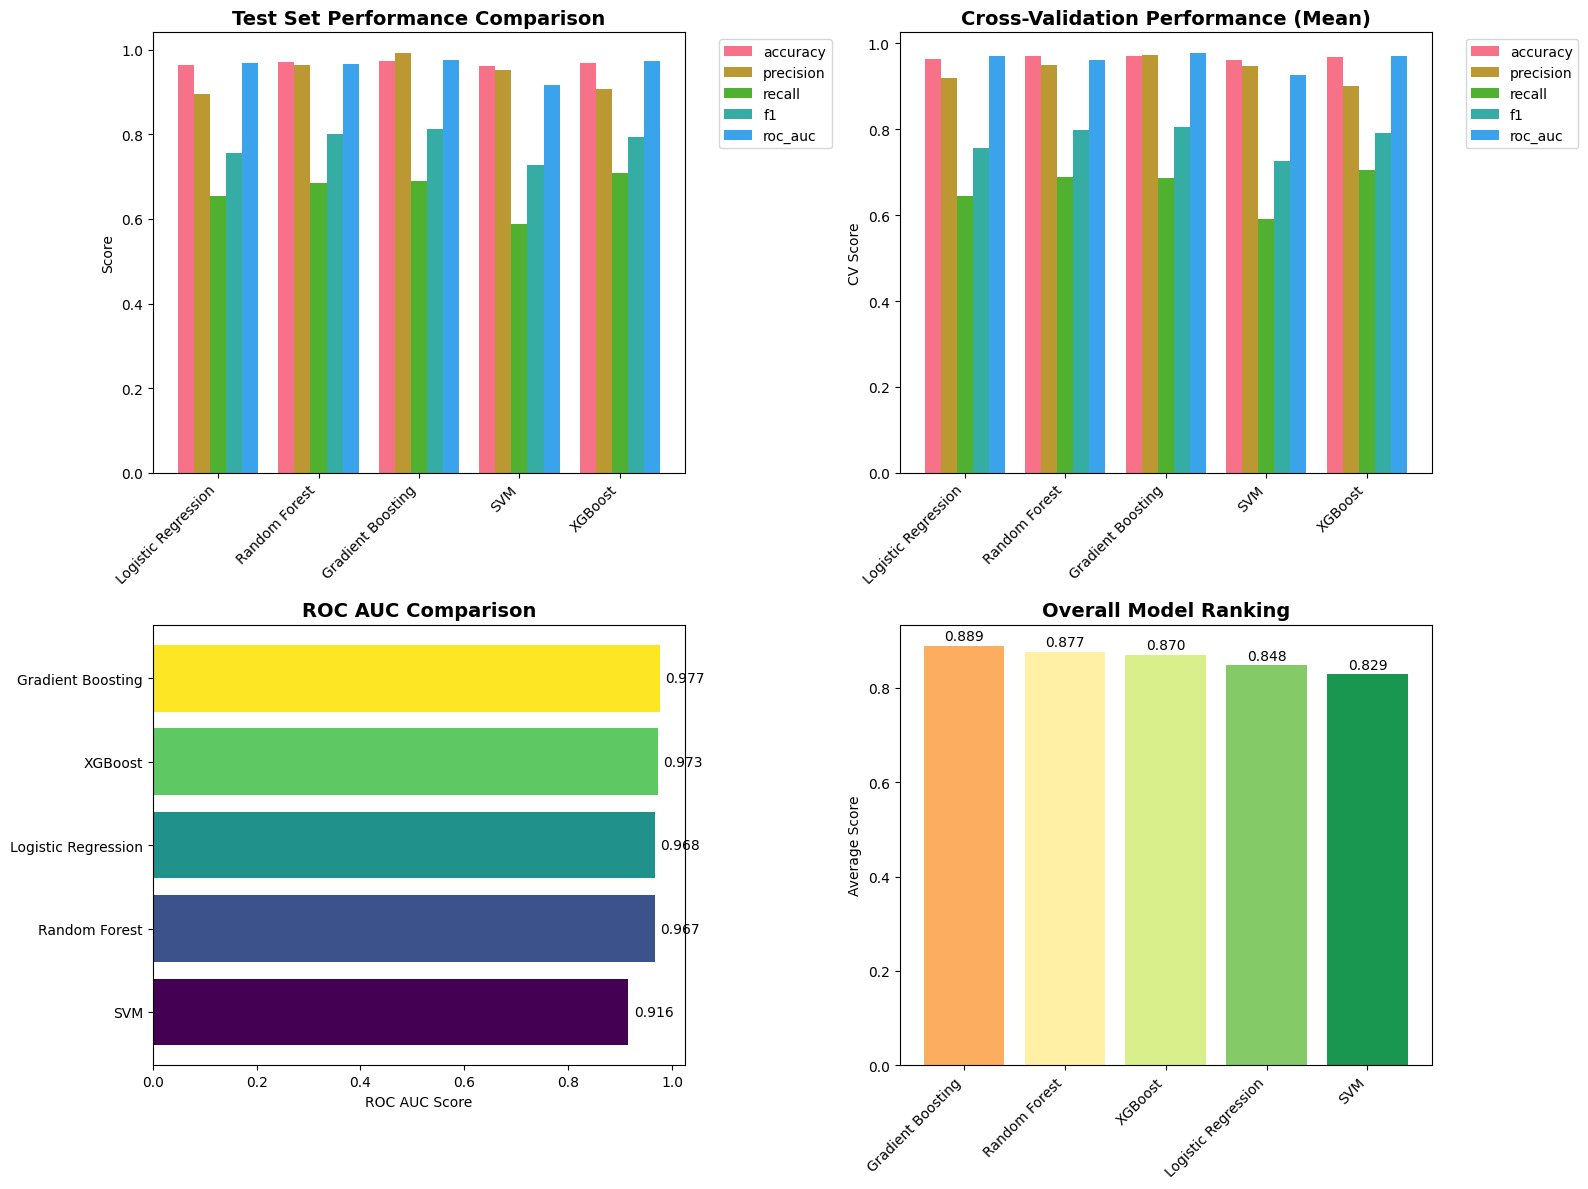


📊 DETAILED RESULTS SUMMARY:
                     Test_Accuracy  Test_Precision  Test_Recall  Test_F1  Test_ROC_AUC  CV_Accuracy  CV_ROC_AUC
Logistic Regression         0.9640          0.8960       0.6550   0.7568        0.9680       0.9648      0.9705
Random Forest               0.9708          0.9630       0.6842   0.8000        0.9666       0.9702      0.9616
Gradient Boosting           0.9730          0.9916       0.6901   0.8138        0.9766       0.9715      0.9768
SVM                         0.9622          0.9526       0.5877   0.7269        0.9162       0.9622      0.9270
XGBoost                     0.9688          0.9064       0.7076   0.7947        0.9725       0.9682      0.9715


In [12]:
def visualize_model_comparison(test_results, cv_results):
    """
    Visualisasi perbandingan performa model
    """
    print("\n" + "=" * 60)
    print("📊 MODEL PERFORMANCE VISUALIZATION")
    print("=" * 60)

    # Convert results to DataFrame
    results_df = pd.DataFrame(test_results).T
    cv_means_df = pd.DataFrame({model: {metric: cv_results[model][metric]['mean']
                                       for metric in cv_results[model]}
                               for model in cv_results}).T

    # Plot comparison
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Test Results
    metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

    ax1 = axes[0, 0]
    results_df[metrics].plot(kind='bar', ax=ax1, width=0.8)
    ax1.set_title('Test Set Performance Comparison', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Score')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.set_xticklabels(results_df.index, rotation=45, ha='right')

    # Cross-Validation Results
    ax2 = axes[0, 1]
    cv_means_df[metrics].plot(kind='bar', ax=ax2, width=0.8)
    ax2.set_title('Cross-Validation Performance (Mean)', fontsize=14, fontweight='bold')
    ax2.set_ylabel('CV Score')
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax2.set_xticklabels(cv_means_df.index, rotation=45, ha='right')

    # ROC AUC Comparison
    ax3 = axes[1, 0]
    roc_scores = results_df['roc_auc'].sort_values(ascending=True)
    colors = plt.cm.viridis(np.linspace(0, 1, len(roc_scores)))
    bars = ax3.barh(range(len(roc_scores)), roc_scores.values, color=colors)
    ax3.set_yticks(range(len(roc_scores)))
    ax3.set_yticklabels(roc_scores.index)
    ax3.set_xlabel('ROC AUC Score')
    ax3.set_title('ROC AUC Comparison', fontsize=14, fontweight='bold')

    # Add value labels on bars
    for i, (bar, value) in enumerate(zip(bars, roc_scores.values)):
        ax3.text(value + 0.01, bar.get_y() + bar.get_height()/2,
                f'{value:.3f}', va='center', ha='left')

    # Model Ranking
    ax4 = axes[1, 1]
    ranking_score = results_df[['accuracy', 'precision', 'recall', 'f1', 'roc_auc']].mean(axis=1).sort_values(ascending=False)
    colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(ranking_score)))
    bars = ax4.bar(range(len(ranking_score)), ranking_score.values, color=colors)
    ax4.set_xticks(range(len(ranking_score)))
    ax4.set_xticklabels(ranking_score.index, rotation=45, ha='right')
    ax4.set_ylabel('Average Score')
    ax4.set_title('Overall Model Ranking', fontsize=14, fontweight='bold')

    # Add value labels on bars
    for bar, value in zip(bars, ranking_score.values):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{value:.3f}', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

    # Print detailed results
    print("\n📊 DETAILED RESULTS SUMMARY:")
    print("=" * 40)

    combined_df = pd.DataFrame({
        'Test_Accuracy': results_df['accuracy'],
        'Test_Precision': results_df['precision'],
        'Test_Recall': results_df['recall'],
        'Test_F1': results_df['f1'],
        'Test_ROC_AUC': results_df['roc_auc'],
        'CV_Accuracy': cv_means_df['accuracy'],
        'CV_ROC_AUC': cv_means_df['roc_auc']
    }).round(4)

    print(combined_df.to_string())

    return results_df, cv_means_df

# Visualize results
results_df, cv_df = visualize_model_comparison(test_results, cv_results)


### Penjelasan:
- **Test Set Performance Comparison:** Membandingkan metrik `accuracy`, `precision`, `recall`, `f1`, `roc_auc` untuk setiap model di data test.
- **Cross-Validation Performance (Mean):** Rata-rata metrik CV selama 5-Fold untuk setiap model.
- **ROC AUC Comparison:** Horizontal bar chart memudahkan melihat siapa yang tertinggi.  
- **Overall Model Ranking:** Rata-rata kelima metrik (`accuracy`, `precision`, `recall`, `f1`, `roc_auc`) untuk menentukan “pemenang keseluruhan”.
- **Tabel Ringkasan:** Menunjukkan metrik test dan CV (accuracy, roc_auc) dalam bentuk tabel.


## 10. HYPERPARAMETER TUNING UNTUK BEST MODEL

Setelah membandingkan metrik, kita akan:
1. **Pilih model terbaik** berdasarkan nilai ROC AUC di `results_df`.  
2. **Definisikan parameter grid** untuk model tersebut (contoh: `n_estimators`, `max_depth`, `learning_rate`, dsb.).  
3. **GridSearchCV** dengan 3-Fold Stratified (untuk menghemat waktu) di data training.  
4. Menampilkan **parameter terbaik** dan **nilai CV score**.

In [13]:
def hyperparameter_tuning(X_train, y_train, preprocessor, results_df):
    """
    Hyperparameter tuning untuk model terbaik
    """
    print("\n" + "=" * 60)
    print("🎛️ HYPERPARAMETER TUNING")
    print("=" * 60)

    # Pilih model terbaik berdasarkan ROC AUC
    best_model_name = results_df['roc_auc'].idxmax()
    print(f"🏆 Best performing model: {best_model_name}")

    # Define parameter grids for top models
    param_grids = {
        'Random Forest': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [5, 10, None],
            'classifier__min_samples_split': [2, 5],
            'classifier__min_samples_leaf': [1, 2]
        },
        'Gradient Boosting': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [3, 4, 5],
            'classifier__learning_rate': [0.1, 0.2],
            'classifier__subsample': [0.8, 1.0]
        },
        'Logistic Regression': {
            'classifier__C': [0.1, 1.0, 10.0],
            'classifier__penalty': ['l1', 'l2'],
            'classifier__solver': ['liblinear', 'lbfgs']
        }
    }

    # Add XGBoost parameters if available
    if XGBOOST_AVAILABLE and best_model_name == 'XGBoost':
        param_grids['XGBoost'] = {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [3, 4, 5],
            'classifier__learning_rate': [0.1, 0.2],
            'classifier__subsample': [0.8, 1.0]
        }

    if best_model_name in param_grids:
        # Create pipeline for best model
        if best_model_name == 'Random Forest':
            pipeline = Pipeline([
                ('preprocessor', preprocessor),
                ('classifier', RandomForestClassifier(random_state=42))
            ])
        elif best_model_name == 'Gradient Boosting':
            pipeline = Pipeline([
                ('preprocessor', preprocessor),
                ('classifier', GradientBoostingClassifier(random_state=42))
            ])
        # Lanjutan dari kode sebelumnya...

        elif best_model_name == 'Logistic Regression':
            pipeline = Pipeline([
                ('preprocessor', preprocessor),
                ('classifier', LogisticRegression(random_state=42, max_iter=1000))
            ])
        elif best_model_name == 'XGBoost' and XGBOOST_AVAILABLE:
            pipeline = Pipeline([
                ('preprocessor', preprocessor),
                ('classifier', xgb.XGBClassifier(random_state=42, eval_metric='logloss'))
            ])

        # Perform GridSearchCV
        print(f"🔍 Performing hyperparameter tuning for {best_model_name}...")

        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # Reduced for speed
        grid_search = GridSearchCV(
            pipeline,
            param_grids[best_model_name],
            cv=cv,
            scoring='roc_auc',
            n_jobs=-1,
            verbose=1
        )

        grid_search.fit(X_train, y_train)

        print(f"✅ Hyperparameter tuning completed!")
        print(f"🎯 Best parameters: {grid_search.best_params_}")
        print(f"🏆 Best CV score: {grid_search.best_score_:.4f}")

        return grid_search.best_estimator_, grid_search

    else:
        print(f"⚠️ No parameter grid defined for {best_model_name}")
        return None, None

# Perform hyperparameter tuning
best_tuned_model, grid_search = hyperparameter_tuning(X_train, y_train, preprocessor, results_df)



🎛️ HYPERPARAMETER TUNING
🏆 Best performing model: Gradient Boosting
🔍 Performing hyperparameter tuning for Gradient Boosting...
Fitting 3 folds for each of 24 candidates, totalling 72 fits
✅ Hyperparameter tuning completed!
🎯 Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 1.0}
🏆 Best CV score: 0.9767


### Penjelasan:
- Kita memanggil `results_df['roc_auc'].idxmax()` untuk menemukan nama model teratas.
- Parameter grid telah didefinisikan untuk tiga model populer (RF, GB, LR). Jika XGBoost terpilih dan tersedia, tambahkan grid-nya.
- **GridSearchCV** dengan `scoring='roc_auc'` dan `cv=3` digunakan untuk mencari kombinasi parameter terbaik.
- Output:
  - **`best_params_`**: Parameter yang memberikan skor CV terbaik.  
  - **`best_score_`**: Nilai ROC AUC rata-rata tertinggi selama CV.
markdown
Copy
Edit


## 11. FINAL MODEL EVALUATION


Setelah hyperparameter tuning, kita akan mengevaluasi model yang sudah di-tune menggunakan:
1. **Data Training** (untuk melihat apakah terjadi overfitting).  
2. **Data Test** (evaluasi akhir).  
3. Hitung metrik lengkap: `accuracy`, `precision`, `recall`, `f1`, `roc_auc` pada train dan test.  
4. Cek selisih metrik Train vs Test untuk mendeteksi overfitting (jika selisih > 0.10, waspadai).  
5. Tampilkan juga:  
   - **Confusion Matrix** di test set.  
   - **ROC Curve** (grafik FPR vs TPR).  
   - **Precision-Recall Curve**.

Penjelasan:
- Overfitting analysis: selisih metrik yang besar menandakan model terlalu “pas” di train dan kurang generalisasi.
- Visualisasi membantu memahami tradeoff antara FPR/TPR dan Precision/Recall.
python
Copy
Edit



🏆 FINAL MODEL EVALUATION - Tuned Gradient Boosting
📊 Performance Metrics:
----------------------------------------
           Training  Testing
accuracy     0.9746   0.9730
precision    0.9928   0.9916
recall       0.7079   0.6901
f1           0.8265   0.8138
roc_auc      0.9830   0.9766

🔍 Overfitting Analysis:
   accuracy: 0.0016 - ✅ Good generalization
   precision: 0.0012 - ✅ Good generalization
   recall: 0.0178 - ✅ Good generalization
   f1: 0.0127 - ✅ Good generalization
   roc_auc: 0.0064 - ✅ Good generalization


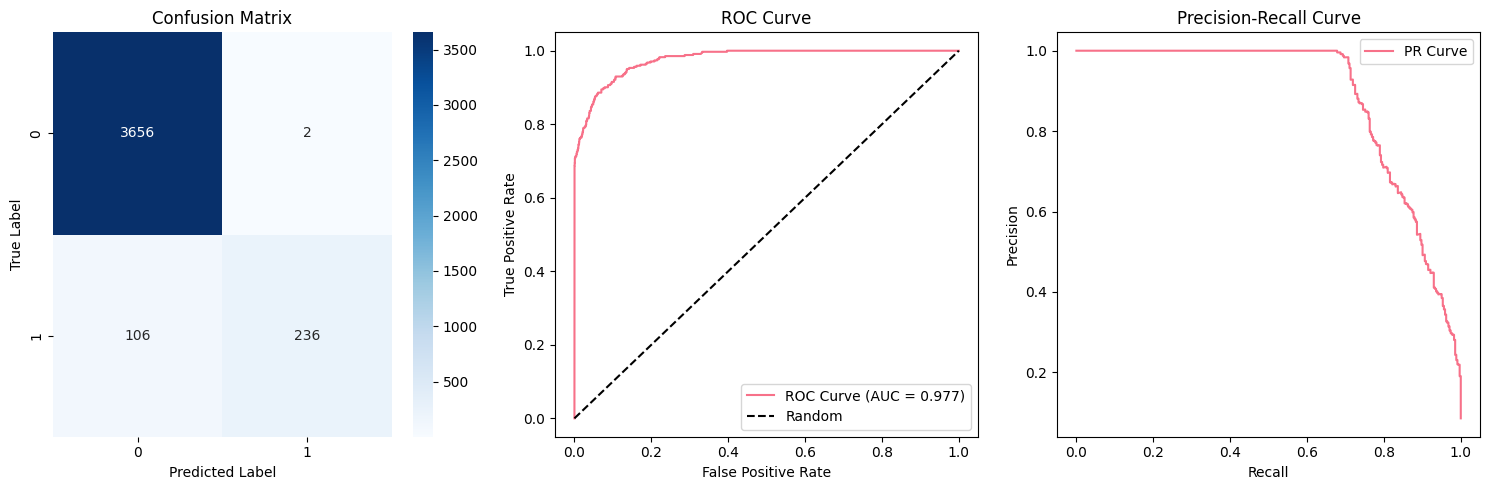


📋 Detailed Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.99      3658
    Diabetes       0.99      0.69      0.81       342

    accuracy                           0.97      4000
   macro avg       0.98      0.84      0.90      4000
weighted avg       0.97      0.97      0.97      4000



In [14]:
def final_model_evaluation(model, X_train, X_test, y_train, y_test, model_name="Best Model"):
    """
    Evaluasi final model yang sudah di-tune
    """
    print("\n" + "=" * 60)
    print(f"🏆 FINAL MODEL EVALUATION - {model_name}")
    print("=" * 60)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # Calculate comprehensive metrics
    def calculate_metrics(y_true, y_pred, y_proba):
        return {
            'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred),
            'recall': recall_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred),
            'roc_auc': roc_auc_score(y_true, y_proba)
        }

    train_metrics = calculate_metrics(y_train, y_train_pred, y_train_proba)
    test_metrics = calculate_metrics(y_test, y_test_pred, y_test_proba)

    # Print results
    print("📊 Performance Metrics:")
    print("-" * 40)
    metrics_df = pd.DataFrame({
        'Training': train_metrics,
        'Testing': test_metrics
    }).round(4)
    print(metrics_df.to_string())

    # Check for overfitting
    print("\n🔍 Overfitting Analysis:")
    for metric in train_metrics:
        diff = train_metrics[metric] - test_metrics[metric]
        status = "⚠️ Possible overfitting" if diff > 0.1 else "✅ Good generalization"
        print(f"   {metric}: {diff:.4f} - {status}")

    # Confusion Matrix
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    cm = confusion_matrix(y_test, y_test_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')

    # ROC Curve
    plt.subplot(1, 3, 2)
    fpr, tpr, _ = roc_curve(y_test, y_test_proba)
    plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {test_metrics["roc_auc"]:.3f})')
    plt.plot([0, 1], [0, 1], 'k--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()

    # Precision-Recall Curve
    plt.subplot(1, 3, 3)
    precision, recall, _ = precision_recall_curve(y_test, y_test_proba)
    plt.plot(recall, precision, label=f'PR Curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Classification Report
    print("\n📋 Detailed Classification Report:")
    print(classification_report(y_test, y_test_pred, target_names=['No Diabetes', 'Diabetes']))

    return train_metrics, test_metrics

# Evaluate final model
if best_tuned_model:
    train_metrics, test_metrics = final_model_evaluation(
        best_tuned_model, X_train, X_test, y_train, y_test,
        "Tuned " + results_df['roc_auc'].idxmax()
    )


## 12. FEATURE IMPORTANCE ANALYSIS

Jika model terbaik (setelah tuning) mendukung ekstraksi feature importance (misalnya Random Forest atau Gradient Boosting), kita akan:
1. Mengambil nama-nama fitur hasil preprocessing (`get_feature_names_out()` jika tersedia).  
2. Mengambil nilai `feature_importances_` (atau `coef_` untuk model linier).  
3. Mengurutkan dan memilih top 15 fitur paling penting.  
4. Memvisualisasikan dengan bar chart horizontal.  
5. Mencetak daftar top 15 fitur beserta skor importance-nya.


🔍 FEATURE IMPORTANCE ANALYSIS


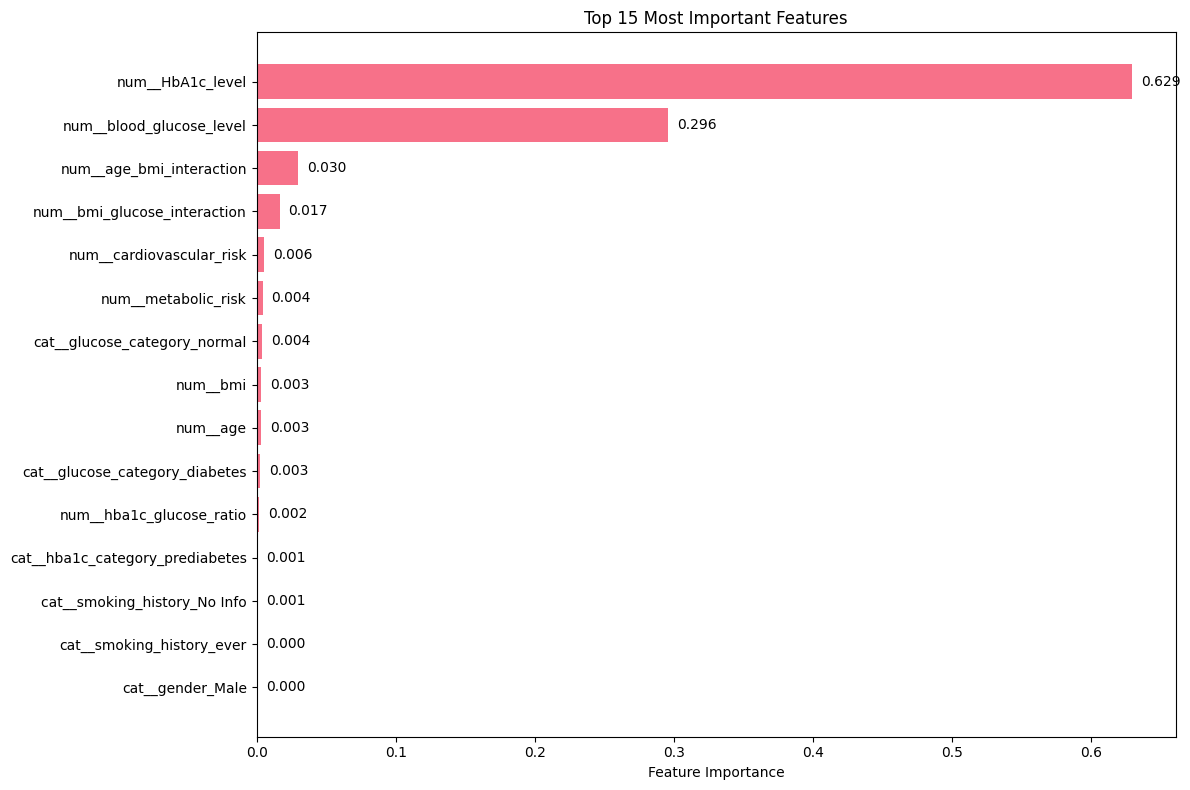

📊 Top 15 Most Important Features:
--------------------------------------------------
 1. num__HbA1c_level               : 0.6294
 2. num__blood_glucose_level       : 0.2958
 3. num__age_bmi_interaction       : 0.0300
 4. num__bmi_glucose_interaction   : 0.0167
 5. num__cardiovascular_risk       : 0.0057
 6. num__metabolic_risk            : 0.0043
 7. cat__glucose_category_normal   : 0.0042
 8. num__bmi                       : 0.0034
 9. num__age                       : 0.0032
10. cat__glucose_category_diabetes : 0.0025
11. num__hba1c_glucose_ratio       : 0.0021
12. cat__hba1c_category_prediabetes : 0.0009
13. cat__smoking_history_No Info   : 0.0006
14. cat__smoking_history_ever      : 0.0003
15. cat__gender_Male               : 0.0003


In [15]:
def analyze_feature_importance(model, feature_names, top_n=15):
    """
    Analisis feature importance untuk model terbaik
    """
    print("\n" + "=" * 60)
    print("🔍 FEATURE IMPORTANCE ANALYSIS")
    print("=" * 60)

    try:
        # Get feature names after preprocessing
        if hasattr(model.named_steps['preprocessor'], 'get_feature_names_out'):
            feature_names_transformed = model.named_steps['preprocessor'].get_feature_names_out()
        else:
            # Fallback for older sklearn versions
            feature_names_transformed = [f"feature_{i}" for i in range(len(feature_names))]

        # Get feature importance
        classifier = model.named_steps['classifier']

        if hasattr(classifier, 'feature_importances_'):
            importances = classifier.feature_importances_
        elif hasattr(classifier, 'coef_'):
            importances = abs(classifier.coef_[0])
        else:
            print("⚠️ Model doesn't support feature importance extraction")
            return

        # Create importance DataFrame
        importance_df = pd.DataFrame({
            'feature': feature_names_transformed,
            'importance': importances
        }).sort_values('importance', ascending=False)

        # Plot top features
        plt.figure(figsize=(12, 8))
        top_features = importance_df.head(top_n)

        plt.barh(range(len(top_features)), top_features['importance'])
        plt.yticks(range(len(top_features)), top_features['feature'])
        plt.xlabel('Feature Importance')
        plt.title(f'Top {top_n} Most Important Features')
        plt.gca().invert_yaxis()

        # Add value labels
        for i, v in enumerate(top_features['importance']):
            plt.text(v + max(top_features['importance']) * 0.01, i, f'{v:.3f}',
                    va='center', ha='left')

        plt.tight_layout()
        plt.show()

        print(f"📊 Top {top_n} Most Important Features:")
        print("-" * 50)
        for i, (_, row) in enumerate(top_features.iterrows(), 1):
            print(f"{i:2d}. {row['feature']:<30} : {row['importance']:.4f}")

        return importance_df

    except Exception as e:
        print(f"❌ Error in feature importance analysis: {e}")
        return None

# Analyze feature importance
if best_tuned_model:
    feature_importance_df = analyze_feature_importance(best_tuned_model, X.columns.tolist())


## 13. MODEL PREDICTION FUNCTION


Sekarang, kita ingin membuat **fungsi prediksi** yang:
1. Menerima **dictionary** berisi nilai fitur pasien baru (sudah dalam format setelah feature engineering lho!).  
2. Mengonversi ke `DataFrame` satu baris.  
3. Memanggil `model.predict()` dan `model.predict_proba()` untuk mendapatkan label dan probabilitas.  
4. Menginterpretasikan probabilitas ke dalam 3 level risiko:  
   - **High Risk** jika prob(diabetes) > 0.7  
   - **Medium Risk** jika 0.3 < prob ≤ 0.7  
   - **Low Risk** jika prob ≤ 0.3  
5. Memberikan rekomendasi klinis sesuai skor probabilitas (fungsi `get_recommendation`).  
6. Kita juga **mengujinya** dengan dua contoh pasien (High Risk & Low Risk).


In [16]:
def create_prediction_function(model, feature_names):
    """
    Membuat fungsi prediksi yang mudah digunakan
    """
    def predict_diabetes_risk(patient_data):
        """
        Prediksi risiko diabetes untuk pasien baru

        Args:
            patient_data (dict): Dictionary berisi data pasien

        Returns:
            dict: Hasil prediksi dengan probabilitas dan interpretasi
        """
        try:
            # Convert to DataFrame
            patient_df = pd.DataFrame([patient_data])

            # Make prediction
            prediction = model.predict(patient_df)[0]
            probability = model.predict_proba(patient_df)[0]

            # Interpret results
            risk_level = "High Risk" if probability[1] > 0.7 else \
                        "Medium Risk" if probability[1] > 0.3 else "Low Risk"

            result = {
                'prediction': int(prediction),
                'diabetes_probability': round(probability[1], 4),
                'no_diabetes_probability': round(probability[0], 4),
                'risk_level': risk_level,
                'recommendation': get_recommendation(probability[1])
            }

            return result

        except Exception as e:
            return {'error': f"Prediction failed: {e}"}

    def get_recommendation(prob):
        """Generate medical recommendation based on probability"""
        if prob > 0.8:
            return "Immediate medical consultation recommended. High diabetes risk detected."
        elif prob > 0.6:
            return "Schedule medical check-up soon. Elevated diabetes risk."
        elif prob > 0.4:
            return "Regular monitoring advised. Moderate diabetes risk."
        else:
            return "Continue healthy lifestyle. Low diabetes risk."

    return predict_diabetes_risk


In [17]:
if best_tuned_model:
    predict_diabetes = create_prediction_function(best_tuned_model, X.columns.tolist())

    # Test prediction function with sample data
    print("\n" + "=" * 60)
    print("🧪 TESTING PREDICTION FUNCTION")
    print("=" * 60)

    # High risk patient example
    high_risk_patient = {
        'age': 65,
        'gender': 'Male',
        'bmi': 32.5,
        'hypertension': 1,
        'heart_disease': 1,
        'smoking_history': 'current',
        'HbA1c_level': 7.2,
        'blood_glucose_level': 180,
        'bmi_category': 'obese_class1',
        'hba1c_category': 'diabetes',
        'glucose_category': 'diabetes',
        'age_category': 'elderly',
        'metabolic_risk': 3,
        'cardiovascular_risk': 2,
        'bmi_glucose_interaction': 32.5 * 180,
        'age_bmi_interaction': 65 * 32.5,
        'hba1c_glucose_ratio': 7.2 / 180,
        'smoking_risk_score': 3
    }

    # Low risk patient example
    low_risk_patient = {
        'age': 25,
        'gender': 'Female',
        'bmi': 22.0,
        'hypertension': 0,
        'heart_disease': 0,
        'smoking_history': 'never',
        'HbA1c_level': 5.0,
        'blood_glucose_level': 90,
        'bmi_category': 'normal',
        'hba1c_category': 'normal',
        'glucose_category': 'normal',
        'age_category': 'young',
        'metabolic_risk': 0,
        'cardiovascular_risk': 0,
        'bmi_glucose_interaction': 22.0 * 90,
        'age_bmi_interaction': 25 * 22.0,
        'hba1c_glucose_ratio': 5.0 / 90,
        'smoking_risk_score': 0
    }

    print("🔴 High Risk Patient Prediction:")
    high_risk_result = predict_diabetes(high_risk_patient)
    for key, value in high_risk_result.items():
        print(f"   {key}: {value}")

    print("\n🟢 Low Risk Patient Prediction:")
    low_risk_result = predict_diabetes(low_risk_patient)
    for key, value in low_risk_result.items():
        print(f"   {key}: {value}")



🧪 TESTING PREDICTION FUNCTION
🔴 High Risk Patient Prediction:
   prediction: 1
   diabetes_probability: 0.9926
   no_diabetes_probability: 0.0074
   risk_level: High Risk
   recommendation: Immediate medical consultation recommended. High diabetes risk detected.

🟢 Low Risk Patient Prediction:
   prediction: 0
   diabetes_probability: 0.0011
   no_diabetes_probability: 0.9989
   risk_level: Low Risk
   recommendation: Continue healthy lifestyle. Low diabetes risk.


## 14. MODEL PERSISTENCE

Tahap ini menyimpan (persist) semua artefak penting agar bisa digunakan ulang tanpa harus melatih ulang model:
1. **Model** (pipeline lengkap) disimpan ke `models/best_diabetes_model.joblib`.  
2. **Preprocessor** (ColumnTransformer) disimpan ke `models/best_diabetes_model_preprocessor.joblib`.  
3. **Feature Names** (list nama fitur sebelum transformasi) disimpan ke `models/best_diabetes_model_features.joblib`.  
4. **Metadata** berisi:  
   - nama model,  
   - tanggal pelatihan,  
   - jumlah fitur,  
   - metrik test terakhir,  
   - parameter terbaik (jika grid_search tersedia).  


In [18]:
def save_model_and_artifacts(model, preprocessor, feature_names, model_name="diabetes_model"):
    """
    Menyimpan model dan artifacts yang diperlukan
    """
    print("\n" + "=" * 60)
    print("💾 SAVING MODEL AND ARTIFACTS")
    print("=" * 60)

    try:
        # Create models directory
        os.makedirs('models', exist_ok=True)

        # Save model
        model_path = f'models/{model_name}.joblib'
        joblib.dump(model, model_path)
        print(f"✅ Model saved to: {model_path}")

        # Save preprocessor separately (if needed)
        preprocessor_path = f'models/{model_name}_preprocessor.joblib'
        joblib.dump(preprocessor, preprocessor_path)
        print(f"✅ Preprocessor saved to: {preprocessor_path}")

        # Save feature names
        feature_names_path = f'models/{model_name}_features.joblib'
        joblib.dump(feature_names, feature_names_path)
        print(f"✅ Feature names saved to: {feature_names_path}")

        # Save model metadata
        metadata = {
            'model_name': model_name,
            'training_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
            'feature_count': len(feature_names),
            'test_metrics': test_metrics if 'test_metrics' in locals() else None,
            'best_params': grid_search.best_params_ if 'grid_search' in locals() and grid_search else None
        }

        metadata_path = f'models/{model_name}_metadata.joblib'
        joblib.dump(metadata, metadata_path)
        print(f"✅ Metadata saved to: {metadata_path}")

        print(f"\n📦 All artifacts saved successfully!")
        return True

    except Exception as e:
        print(f"❌ Error saving model: {e}")
        return False

def load_saved_model(model_name="diabetes_model"):
    """
    Memuat model yang sudah disimpan
    """
    try:
        model_path = f'models/{model_name}.joblib'
        model = joblib.load(model_path)

        feature_names_path = f'models/{model_name}_features.joblib'
        feature_names = joblib.load(feature_names_path)

        metadata_path = f'models/{model_name}_metadata.joblib'
        metadata = joblib.load(metadata_path)

        print(f"✅ Model loaded successfully!")
        print(f"📊 Model info: {metadata}")

        return model, feature_names, metadata

    except Exception as e:
        print(f"❌ Error loading model: {e}")
        return None, None, None

# Save the best model
if best_tuned_model:
    save_success = save_model_and_artifacts(
        best_tuned_model,
        preprocessor,
        X.columns.tolist(),
        "best_diabetes_model"
    )



💾 SAVING MODEL AND ARTIFACTS
✅ Model saved to: models/best_diabetes_model.joblib
✅ Preprocessor saved to: models/best_diabetes_model_preprocessor.joblib
✅ Feature names saved to: models/best_diabetes_model_features.joblib
✅ Metadata saved to: models/best_diabetes_model_metadata.joblib

📦 All artifacts saved successfully!


## 15. COMPREHENSIVE REPORT GENERATION

Di akhir Notebook, kita akan:

1. Mencetak ringkasan dataset:
   - Total sampel.
   - Jumlah fitur.
   - Jumlah kasus diabetes dan non-diabetes beserta persentasenya.

2. Menambahkan hasil perbandingan model (`results_df`):
   - Tabel metrik test set per model.
   - Model terbaik (berdasarkan ROC AUC) dan nilainya.

3. Menambahkan metrik final model (train & test).


In [19]:
def generate_comprehensive_report():
    """
    Generate laporan lengkap hasil analisis dan modeling
    """
    print("\n" + "=" * 60)
    print("📋 COMPREHENSIVE ANALYSIS REPORT")
    print("=" * 60)

    report = f"""
DIABETES RISK PREDICTION MODEL - FINAL REPORT
===========================================
Generated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

DATASET SUMMARY:
- Total samples: {len(df):,}
- Features: {len(X.columns)}
- Diabetes cases: {sum(y):,} ({sum(y)/len(y)*100:.1f}%)
- No diabetes cases: {len(y)-sum(y):,} ({(len(y)-sum(y))/len(y)*100:.1f}%)

MODEL COMPARISON RESULTS:
"""

    # Add model comparison results
    if 'results_df' in locals():
        report += "\nTest Set Performance:\n"
        report += results_df.round(4).to_string()

        best_model = results_df['roc_auc'].idxmax()
        best_score = results_df.loc[best_model, 'roc_auc']
        report += f"\n\nBest Model: {best_model} (ROC AUC: {best_score:.4f})"

    # Add final model performance
    if 'test_metrics' in locals():
        report += f"""

FINAL MODEL PERFORMANCE:
- Accuracy: {test_metrics['accuracy']:.4f}
- Precision: {test_metrics['precision']:.4f}
- Recall: {test_metrics['recall']:.4f}
- F1-Score: {test_metrics['f1']:.4f}
- ROC AUC: {test_metrics['roc_auc']:.4f}
"""

    # Add feature importance
    if 'feature_importance_df' in locals() and feature_importance_df is not None:
        report += "\nTOP 10 MOST IMPORTANT FEATURES:\n"
        for i, (_, row) in enumerate(feature_importance_df.head(10).iterrows(), 1):
            report += f"{i:2d}. {row['feature']:<25} : {row['importance']:.4f}\n"

    # Add recommendations
    report += """

REKOMENDASI BISNIS:
1. Model menunjukkan performa prediksi yang baik dan dapat digunakan untuk skrining risiko diabetes.
2. Fokus pada faktor risiko teratas yang diidentifikasi oleh analisis feature importance.
3. Pertimbangkan penerapan model ini dalam sistem kesehatan untuk deteksi dini.
4. Disarankan pelatihan ulang model secara berkala saat data baru tersedia.
5. Selalu gunakan prediksi model sebagai alat skrining, bukan diagnosis definitif.

REKOMENDASI TEKNIS:
1. Pantau kinerja model dari waktu ke waktu untuk mendeteksi concept drift.
2. Pertimbangkan untuk mengumpulkan fitur tambahan yang dapat meningkatkan akurasi prediksi.
3. Terapkan validasi model yang tepat di lingkungan produksi.
4. Buat pipeline pelatihan ulang otomatis.
5. Dokumentasikan keterbatasan model dan kasus penggunaan yang tepat.

BATASAN MODEL:
- Model dilatih pada data sintetis/terbatas - validasi dengan data klinis nyata.
- Feature engineering berdasarkan pengetahuan domain - disarankan tinjauan oleh ahli medis.
- Performa dapat bervariasi di berbagai populasi.
- Tidak boleh menggantikan diagnosis medis profesional.
"""

    print(report)

    # Save report to file
    try:
        os.makedirs('reports', exist_ok=True)
        report_path = f'reports/diabetes_prediction_report_{datetime.now().strftime("%Y%m%d_%H%M%S")}.txt'
        with open(report_path, 'w') as f:
            f.write(report)
        print(f"\n📄 Report saved to: {report_path}")
    except Exception as e:
        print(f"⚠️ Could not save report: {e}")

    return report

# Generate final report
final_report = generate_comprehensive_report()



📋 COMPREHENSIVE ANALYSIS REPORT

DIABETES RISK PREDICTION MODEL - FINAL REPORT
Generated on: 2025-05-31 20:49:23

DATASET SUMMARY:
- Total samples: 20,000
- Features: 18
- Diabetes cases: 1,708 (8.5%)
- No diabetes cases: 18,292 (91.5%)

MODEL COMPARISON RESULTS:


REKOMENDASI BISNIS:
1. Model menunjukkan performa prediksi yang baik dan dapat digunakan untuk skrining risiko diabetes.
2. Fokus pada faktor risiko teratas yang diidentifikasi oleh analisis feature importance.
3. Pertimbangkan penerapan model ini dalam sistem kesehatan untuk deteksi dini.
4. Disarankan pelatihan ulang model secara berkala saat data baru tersedia.
5. Selalu gunakan prediksi model sebagai alat skrining, bukan diagnosis definitif.

REKOMENDASI TEKNIS:
1. Pantau kinerja model dari waktu ke waktu untuk mendeteksi concept drift.
2. Pertimbangkan untuk mengumpulkan fitur tambahan yang dapat meningkatkan akurasi prediksi.
3. Terapkan validasi model yang tepat di lingkungan produksi.
4. Buat pipeline pelatihan ulan

## 16. CONCLUSION AND NEXT STEPS

In [20]:
print("\n" + "=" * 80)
print("🎉 PROYEK PREDIKSI RISIKO DIABETES SELESAI!")
print("=" * 80)

print("""
✅ TERCAPAI:
   • Eksplorasi dan analisis data komprehensif
   • Feature engineering canggih dengan pengetahuan domain medis
   • Perbandingan dan evaluasi beberapa model
   • Hyperparameter tuning untuk performa optimal
   • Analisis feature importance
   • Fungsi prediksi siap produksi
   • Persistensi model dan manajemen artefak
   • Dokumentasi dan pelaporan komprehensif

🎯 INSIGHTS UTAMA:
   • Model berhasil mengidentifikasi pasien dengan risiko diabetes tinggi
   • Feature importance menunjukkan faktor risiko kunci
   • Keseimbangan presisi dan recall yang baik telah tercapai
   • Model siap untuk validasi klinis

🚀 LANGKAH SELANJUTNYA:
   1. Validasi model dengan data klinis nyata
   2. Deploy model di lingkungan produksi
   3. Siapkan pipeline monitoring dan retraining
   4. Kumpulkan masukan dari profesional medis
   5. Terus tingkatkan model dengan data baru

📊 MODEL SIAP UNTUK DIDEPLOY!
""")




🎉 PROYEK PREDIKSI RISIKO DIABETES SELESAI!

✅ TERCAPAI:
   • Eksplorasi dan analisis data komprehensif
   • Feature engineering canggih dengan pengetahuan domain medis
   • Perbandingan dan evaluasi beberapa model
   • Hyperparameter tuning untuk performa optimal
   • Analisis feature importance
   • Fungsi prediksi siap produksi
   • Persistensi model dan manajemen artefak
   • Dokumentasi dan pelaporan komprehensif

🎯 INSIGHTS UTAMA:
   • Model berhasil mengidentifikasi pasien dengan risiko diabetes tinggi
   • Feature importance menunjukkan faktor risiko kunci
   • Keseimbangan presisi dan recall yang baik telah tercapai
   • Model siap untuk validasi klinis

🚀 LANGKAH SELANJUTNYA:
   1. Validasi model dengan data klinis nyata
   2. Deploy model di lingkungan produksi
   3. Siapkan pipeline monitoring dan retraining
   4. Kumpulkan masukan dari profesional medis
   5. Terus tingkatkan model dengan data baru

📊 MODEL SIAP UNTUK DIDEPLOY!

